# EXPLORATORY DATA ANALYSIS

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import Image, display
from scipy.stats import fisher_exact, kruskal, mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src import data_loader

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)

## Exploration of Raw Dataset

This section aims to understand the dataset at a structural level. In this phase, the objective is to determine data consistancy, considering things as data type, missing values, possible data imbalance, number of observations and number of features.

In [2]:
# Load the dataset.
cancer_df = data_loader.load_data(
    file_name='cancer_dataset.xls', 
    folder='external',
    index_col=0
)

Successfully loaded: C:\Users\sebas\OneDrive - The University of Nottingham\University of Nottingham - MSc Data Science\Machine Learning (20cr)\Projects\Machine Learning Breast Cancer\data\external\cancer_dataset.xls


##### Shape of the dataset

In [3]:
# Display the first 5 rows of the dataset.
cancer_df.head(5)

,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,original_shape_Sphericity,original_shape_SurfaceArea,original_shape_SurfaceVolumeRatio,original_shape_VoxelVolume,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,original_firstorder_Minimum,original_firstorder_Range,original_firstorder_RobustMeanAbsoluteDeviation,original_firstorder_RootMeanSquared,original_firstorder_Skewness,original_firstorder_TotalEnergy,original_firstorder_Uniformity,original_firstorder_Variance,original_glcm_Autocorrelation,original_glcm_ClusterProminence,original_glcm_ClusterShade,original_glcm_ClusterTendency,original_glcm_Contrast,original_glcm_Correlation,original_glcm_DifferenceAverage,original_glcm_DifferenceEntropy,original_glcm_DifferenceVariance,original_glcm_Id,original_glcm_Idm,original_glcm_Idmn,original_glcm_Idn,original_glcm_Imc1,original_glcm_Imc2,original_glcm_InverseVariance,original_glcm_JointAverage,original_glcm_JointEnergy,original_glcm_JointEntropy,original_glcm_MCC,original_glcm_MaximumProbability,original_glcm_SumAverage,original_glcm_SumEntropy,original_glcm_SumSquares,original_gldm_DependenceEntropy,original_gldm_DependenceNonUniformity,original_gldm_DependenceNonUniformityNormalized,original_gldm_DependenceVariance,original_gldm_GrayLevelNonUniformity,original_gldm_GrayLevelVariance,original_gldm_HighGrayLevelEmphasis,original_gldm_LargeDependenceEmphasis,original_gldm_LargeDependenceHighGrayLevelEmphasis,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_glrlm_GrayLevelNonUniformity,original_glrlm_GrayLevelNonUniformityNormalized,original_glrlm_GrayLevelVariance,original_glrlm_HighGrayLevelRunEmphasis,original_glrlm_LongRunEmphasis,original_glrlm_LongRunHighGrayLevelEmphasis,original_glrlm_LongRunLowGrayLevelEmphasis,original_glrlm_LowGrayLevelRunEmphasis,original_glrlm_RunEntropy,original_glrlm_RunLengthNonUniformity,original_glrlm_RunLengthNonUniformityNormalized,original_glrlm_RunPercentage,original_glrlm_RunVariance,original_glrlm_ShortRunEmphasis,original_glrlm_ShortRunHighGrayLevelEmphasis,original_glrlm_ShortRunLowGrayLevelEmphasis,original_glszm_GrayLevelNonUniformity,original_glszm_GrayLevelNonUniformityNormalized,original_glszm_GrayLevelVariance,original_glszm_HighGrayLevelZoneEmphasis,original_glszm_LargeAreaEmphasis,original_glszm_LargeAreaHighGrayLevelEmphasis,original_glszm_LargeAreaLowGrayLevelEmphasis,original_glszm_LowGrayLevelZoneEmphasis,original_glszm_SizeZoneNonUniformity,original_glszm_SizeZoneNonUniformityNormalized,original_glszm_SmallAreaEmphasis,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TRG002174,1,144.0,41.0,0,0,0,1,3,3,1,1,2,1,0.8139,0.7241,23.7819,32.8444,37.6962,38.6264,34.7131,39.5727,14209.4583,26.7324,0.7717,3676.5000,0.2587,14263,-0.1635,0.7089,2897.6893,0.7381,0.4065,4.5946,2.1148,0.2

In [4]:
# Get the shape of the dataset.
print(f"Dataset (rows x cols): {cancer_df.shape}")

Dataset (rows x cols): (400, 120)


##### Analysis of required preprocessing

In [5]:
# First check if there are any missing values in the dataset.
print(f"Missing Values: {cancer_df.isnull().sum().sum()}")

Missing Values: 0


In [6]:
# Since sometimes missing values are not inmediately visible, let's check the distributions.
cancer_df.describe()

,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,original_shape_Sphericity,original_shape_SurfaceArea,original_shape_SurfaceVolumeRatio,original_shape_VoxelVolume,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,original_firstorder_Minimum,original_firstorder_Range,original_firstorder_RobustMeanAbsoluteDeviation,original_firstorder_RootMeanSquared,original_firstorder_Skewness,original_firstorder_TotalEnergy,original_firstorder_Uniformity,original_firstorder_Variance,original_glcm_Autocorrelation,original_glcm_ClusterProminence,original_glcm_ClusterShade,original_glcm_ClusterTendency,original_glcm_Contrast,original_glcm_Correlation,original_glcm_DifferenceAverage,original_glcm_DifferenceEntropy,original_glcm_DifferenceVariance,original_glcm_Id,original_glcm_Idm,original_glcm_Idmn,original_glcm_Idn,original_glcm_Imc1,original_glcm_Imc2,original_glcm_InverseVariance,original_glcm_JointAverage,original_glcm_JointEnergy,original_glcm_JointEntropy,original_glcm_MCC,original_glcm_MaximumProbability,original_glcm_SumAverage,original_glcm_SumEntropy,original_glcm_SumSquares,original_gldm_DependenceEntropy,original_gldm_DependenceNonUniformity,original_gldm_DependenceNonUniformityNormalized,original_gldm_DependenceVariance,original_gldm_GrayLevelNonUniformity,original_gldm_GrayLevelVariance,original_gldm_HighGrayLevelEmphasis,original_gldm_LargeDependenceEmphasis,original_gldm_LargeDependenceHighGrayLevelEmphasis,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_glrlm_GrayLevelNonUniformity,original_glrlm_GrayLevelNonUniformityNormalized,original_glrlm_GrayLevelVariance,original_glrlm_HighGrayLevelRunEmphasis,original_glrlm_LongRunEmphasis,original_glrlm_LongRunHighGrayLevelEmphasis,original_glrlm_LongRunLowGrayLevelEmphasis,original_glrlm_LowGrayLevelRunEmphasis,original_glrlm_RunEntropy,original_glrlm_RunLengthNonUniformity,original_glrlm_RunLengthNonUniformityNormalized,original_glrlm_RunPercentage,original_glrlm_RunVariance,original_glrlm_ShortRunEmphasis,original_glrlm_ShortRunHighGrayLevelEmphasis,original_glrlm_ShortRunLowGrayLevelEmphasis,original_glszm_GrayLevelNonUniformity,original_glszm_GrayLevelNonUniformityNormalized,original_glszm_GrayLevelVariance,original_glszm_HighGrayLevelZoneEmphasis,original_glszm_LargeAreaEmphasis,original_glszm_LargeAreaHighGrayLevelEmphasis,original_glszm_LargeAreaLowGrayLevelEmphasis,original_glszm_LowGrayLevelZoneEmphasis,original_glszm_SizeZoneNonUniformity,original_glszm_SizeZoneNonUniformityNormalized,original_glszm_SmallAreaEmphasis,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
count,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000,4.0000e+02,4.0000e+02,400.0000,400.0000,400.0000,400.0000,400.0000

In [7]:
# Count the number of '999' on each column.
cancer_df[cancer_df == 999].count(axis=0)

pCR (outcome)                                          5
RelapseFreeSurvival (outcome)                          0
Age                                                    0
ER                                                     0
PgR                                                    1
HER2                                                   1
TrippleNegative                                        1
ChemoGrade                                             3
Proliferation                                          2
HistologyType                                          3
LNStatus                                               1
TumourStage                                            0
Gene                                                  88
original_shape_Elongation                              0
original_shape_Flatness                                0
original_shape_LeastAxisLength                         0
original_shape_MajorAxisLength                         0
original_shape_Maximum2DDiamete

In [8]:
# Check data balance of pCR outcome.
print("Number of patients with successful chemotherapy:")
print(cancer_df[cancer_df['pCR (outcome)'] == 1].shape[0])

print("\n")

print("Number of patients with residual cancer:") 
print(cancer_df[cancer_df['pCR (outcome)'] == 0].shape[0])

Number of patients with successful chemotherapy:
84


Number of patients with residual cancer:
311


In [9]:
print(f"Number of patients with successful treatment but missing Gene information: {cancer_df[(cancer_df['Gene'] == 999) & (cancer_df['pCR (outcome)'] == 1)].shape[0]}")

Number of patients with successful treatment but missing Gene information: 30


In [10]:
# ID column
id_column = ['ID']

# Define target columns.
target_columns = [
    'pCR (outcome)',
    'RelapseFreeSurvival (outcome)'
]

# Separate clinical and image features.
clinical_features = [
    'Age',
    'ER',
    'PgR',
    'HER2',
    'TrippleNegative',
    'ChemoGrade',
    'Proliferation',
    'HistologyType',
    'LNStatus',
    'TumourStage',
    'Gene'
]

image_features = (cols for cols in cancer_df.columns if cols not in clinical_features + target_columns + id_column)

In [11]:
# Print unique values on each clinical feature.
for col in cancer_df[clinical_features].columns:
    print(f"Unique values on {col}: {np.unique(cancer_df[col])}")   # using numpy so that they are automatically sorted in ascending order.


Unique values on Age: [23.       26.       28.3      28.960986 29.670089 30.365503 31.
 31.6      31.78371  31.9      32.936345 33.002053 33.034908 33.347023
 33.5      33.7      34.201232 34.28063  34.3      34.390144 34.67488
 35.       35.277207 35.386721 35.405886 35.6      35.994524 36.
 36.265572 36.558522 36.6      36.783025 36.9      36.939083 36.985626
 37.       37.514031 37.9      38.143737 38.3      38.5      38.7
 38.78987  38.8      38.9      39.       39.1      39.646817 39.753593
 40.       40.210815 40.336756 40.391513 41.       41.100616 41.3
 41.760438 41.889117 42.       42.020534 42.475017 42.7      42.767967
 43.       43.049966 43.162218 43.252567 43.540041 43.559206 43.682409
 43.770021 43.986311 44.       44.205339 44.243669 44.607803 44.618754
 44.657084 44.684463 45.       45.054073 45.3      45.385353 45.585216
 45.653662 45.785079 45.8      45.806982 46.       46.102669 46.162902
 46.231348 46.294319 46.414784 46.614647 46.639288 46.7      47.
 47.1      47

In [12]:
# Check data type of clinical fetures.
print(cancer_df[clinical_features].dtypes)

Age                float64
ER                   int64
PgR                  int64
HER2                 int64
TrippleNegative      int64
ChemoGrade           int64
Proliferation        int64
HistologyType        int64
LNStatus             int64
TumourStage          int64
Gene                 int64
dtype: object


In [13]:
# Confirm data types on the non-clinical features.
cancer_df[image_features].dtypes

original_shape_Elongation                             float64
original_shape_Flatness                               float64
original_shape_LeastAxisLength                        float64
original_shape_MajorAxisLength                        float64
original_shape_Maximum2DDiameterColumn                float64
original_shape_Maximum2DDiameterRow                   float64
original_shape_Maximum2DDiameterSlice                 float64
original_shape_Maximum3DDiameter                      float64
original_shape_MeshVolume                             float64
original_shape_MinorAxisLength                        float64
original_shape_Sphericity                             float64
original_shape_SurfaceArea                            float64
original_shape_SurfaceVolumeRatio                     float64
original_shape_VoxelVolume                              int64
original_firstorder_10Percentile                      float64
original_firstorder_90Percentile                      float64
original

## Pre-processed Data Analysis

This second exploratory analysis will be focused on the statistical shape of the clean dataset. Hence, investigating the distribution within each feature, colinearity, correlation with other features and patterns to explain the targets.

In [14]:
# Load processed dataset.
cancer_features = data_loader.load_data(
    file_name='preprocessed_cancer_features.xlsx', 
    folder='processed',
    index_col=None
)

cancer_targets = data_loader.load_data(
    file_name='preprocessed_cancer_targets.xlsx', 
    folder='processed',
    index_col=None
)

Successfully loaded: C:\Users\sebas\OneDrive - The University of Nottingham\University of Nottingham - MSc Data Science\Machine Learning (20cr)\Projects\Machine Learning Breast Cancer\data\processed\preprocessed_cancer_features.xlsx
Successfully loaded: C:\Users\sebas\OneDrive - The University of Nottingham\University of Nottingham - MSc Data Science\Machine Learning (20cr)\Projects\Machine Learning Breast Cancer\data\processed\preprocessed_cancer_targets.xlsx


In [15]:
cancer_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Columns: 118 entries, Age to original_ngtdm_Strength
dtypes: float64(106), int64(12)
memory usage: 364.3 KB


In [16]:
# Check that the dataframe has been preprocessed correctly.
cancer_features.describe()

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType_1.0,HistologyType_2.0,LNStatus,TumourStage,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,original_shape_Sphericity,original_shape_SurfaceArea,original_shape_SurfaceVolumeRatio,original_shape_VoxelVolume,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,original_firstorder_Minimum,original_firstorder_Range,original_firstorder_RobustMeanAbsoluteDeviation,original_firstorder_RootMeanSquared,original_firstorder_Skewness,original_firstorder_TotalEnergy,original_firstorder_Uniformity,original_firstorder_Variance,original_glcm_Autocorrelation,original_glcm_ClusterProminence,original_glcm_ClusterShade,original_glcm_ClusterTendency,original_glcm_Contrast,original_glcm_Correlation,original_glcm_DifferenceAverage,original_glcm_DifferenceEntropy,original_glcm_DifferenceVariance,original_glcm_Id,original_glcm_Idm,original_glcm_Idmn,original_glcm_Idn,original_glcm_Imc1,original_glcm_Imc2,original_glcm_InverseVariance,original_glcm_JointAverage,original_glcm_JointEnergy,original_glcm_JointEntropy,original_glcm_MCC,original_glcm_MaximumProbability,original_glcm_SumAverage,original_glcm_SumEntropy,original_glcm_SumSquares,original_gldm_DependenceEntropy,original_gldm_DependenceNonUniformity,original_gldm_DependenceNonUniformityNormalized,original_gldm_DependenceVariance,original_gldm_GrayLevelNonUniformity,original_gldm_GrayLevelVariance,original_gldm_HighGrayLevelEmphasis,original_gldm_LargeDependenceEmphasis,original_gldm_LargeDependenceHighGrayLevelEmphasis,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_glrlm_GrayLevelNonUniformity,original_glrlm_GrayLevelNonUniformityNormalized,original_glrlm_GrayLevelVariance,original_glrlm_HighGrayLevelRunEmphasis,original_glrlm_LongRunEmphasis,original_glrlm_LongRunHighGrayLevelEmphasis,original_glrlm_LongRunLowGrayLevelEmphasis,original_glrlm_LowGrayLevelRunEmphasis,original_glrlm_RunEntropy,original_glrlm_RunLengthNonUniformity,original_glrlm_RunLengthNonUniformityNormalized,original_glrlm_RunPercentage,original_glrlm_RunVariance,original_glrlm_ShortRunEmphasis,original_glrlm_ShortRunHighGrayLevelEmphasis,original_glrlm_ShortRunLowGrayLevelEmphasis,original_glszm_GrayLevelNonUniformity,original_glszm_GrayLevelNonUniformityNormalized,original_glszm_GrayLevelVariance,original_glszm_HighGrayLevelZoneEmphasis,original_glszm_LargeAreaEmphasis,original_glszm_LargeAreaHighGrayLevelEmphasis,original_glszm_LargeAreaLowGrayLevelEmphasis,original_glszm_LowGrayLevelZoneEmphasis,original_glszm_SizeZoneNonUniformity,original_glszm_SizeZoneNonUniformityNormalized,original_glszm_SmallAreaEmphasis,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
count,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,3.9500e+02,3.9500e+02,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000,395.0000

In [17]:
# Check all data types of the features.
cancer_features.dtypes

Age                                                     int64
ER                                                      int64
PgR                                                     int64
HER2                                                    int64
TrippleNegative                                         int64
ChemoGrade                                              int64
Proliferation                                           int64
HistologyType_1.0                                       int64
HistologyType_2.0                                       int64
LNStatus                                                int64
TumourStage                                             int64
original_shape_Elongation                             float64
original_shape_Flatness                               float64
original_shape_LeastAxisLength                        float64
original_shape_MajorAxisLength                        float64
original_shape_Maximum2DDiameterColumn                float64
original

##### Analysis for classification task

In [18]:
# Merge features and targets to inspect the correlation between features and target.
processed_cancer_df = pd.concat(
    [cancer_targets, cancer_features], 
    axis=1
)

print(processed_cancer_df.isnull().sum().sum())
processed_cancer_df.head(5)

0


,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType_1.0,HistologyType_2.0,LNStatus,TumourStage,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,original_shape_Sphericity,original_shape_SurfaceArea,original_shape_SurfaceVolumeRatio,original_shape_VoxelVolume,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy,original_firstorder_Entropy,original_firstorder_InterquartileRange,original_firstorder_Kurtosis,original_firstorder_Maximum,original_firstorder_MeanAbsoluteDeviation,original_firstorder_Mean,original_firstorder_Median,original_firstorder_Minimum,original_firstorder_Range,original_firstorder_RobustMeanAbsoluteDeviation,original_firstorder_RootMeanSquared,original_firstorder_Skewness,original_firstorder_TotalEnergy,original_firstorder_Uniformity,original_firstorder_Variance,original_glcm_Autocorrelation,original_glcm_ClusterProminence,original_glcm_ClusterShade,original_glcm_ClusterTendency,original_glcm_Contrast,original_glcm_Correlation,original_glcm_DifferenceAverage,original_glcm_DifferenceEntropy,original_glcm_DifferenceVariance,original_glcm_Id,original_glcm_Idm,original_glcm_Idmn,original_glcm_Idn,original_glcm_Imc1,original_glcm_Imc2,original_glcm_InverseVariance,original_glcm_JointAverage,original_glcm_JointEnergy,original_glcm_JointEntropy,original_glcm_MCC,original_glcm_MaximumProbability,original_glcm_SumAverage,original_glcm_SumEntropy,original_glcm_SumSquares,original_gldm_DependenceEntropy,original_gldm_DependenceNonUniformity,original_gldm_DependenceNonUniformityNormalized,original_gldm_DependenceVariance,original_gldm_GrayLevelNonUniformity,original_gldm_GrayLevelVariance,original_gldm_HighGrayLevelEmphasis,original_gldm_LargeDependenceEmphasis,original_gldm_LargeDependenceHighGrayLevelEmphasis,original_gldm_LargeDependenceLowGrayLevelEmphasis,original_gldm_LowGrayLevelEmphasis,original_gldm_SmallDependenceEmphasis,original_gldm_SmallDependenceHighGrayLevelEmphasis,original_gldm_SmallDependenceLowGrayLevelEmphasis,original_glrlm_GrayLevelNonUniformity,original_glrlm_GrayLevelNonUniformityNormalized,original_glrlm_GrayLevelVariance,original_glrlm_HighGrayLevelRunEmphasis,original_glrlm_LongRunEmphasis,original_glrlm_LongRunHighGrayLevelEmphasis,original_glrlm_LongRunLowGrayLevelEmphasis,original_glrlm_LowGrayLevelRunEmphasis,original_glrlm_RunEntropy,original_glrlm_RunLengthNonUniformity,original_glrlm_RunLengthNonUniformityNormalized,original_glrlm_RunPercentage,original_glrlm_RunVariance,original_glrlm_ShortRunEmphasis,original_glrlm_ShortRunHighGrayLevelEmphasis,original_glrlm_ShortRunLowGrayLevelEmphasis,original_glszm_GrayLevelNonUniformity,original_glszm_GrayLevelNonUniformityNormalized,original_glszm_GrayLevelVariance,original_glszm_HighGrayLevelZoneEmphasis,original_glszm_LargeAreaEmphasis,original_glszm_LargeAreaHighGrayLevelEmphasis,original_glszm_LargeAreaLowGrayLevelEmphasis,original_glszm_LowGrayLevelZoneEmphasis,original_glszm_SizeZoneNonUniformity,original_glszm_SizeZoneNonUniformityNormalized,original_glszm_SmallAreaEmphasis,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,1,144.0,41,0,0,0,1,3,3,1,0,1,2,0.8139,0.7241,23.7819,32.8444,37.6962,38.6264,34.7131,39.5727,14209.4583,26.7324,0.7717,3676.5000,0.2587,14263,-0.1635,0.7089,2897.6893,0.7381,0.4065,4.5946,2.1148,0.2780,0.2482,0.2176,-1.2518,3.3666,0.1740,0.4507,0.3862,2897.6893,0.6703,0.1416,3.3288,0.7258,-0.4253,0.4388,0.1843,0.

In [19]:
# List of new categorical features.
categorical_features = [
    'ER',
    'PgR',
    'HER2',
    'TrippleNegative',
    'ChemoGrade',
    'Proliferation',
    'HistologyType_1.0',
    'HistologyType_2.0',
    'LNStatus',
    'TumourStage'
]

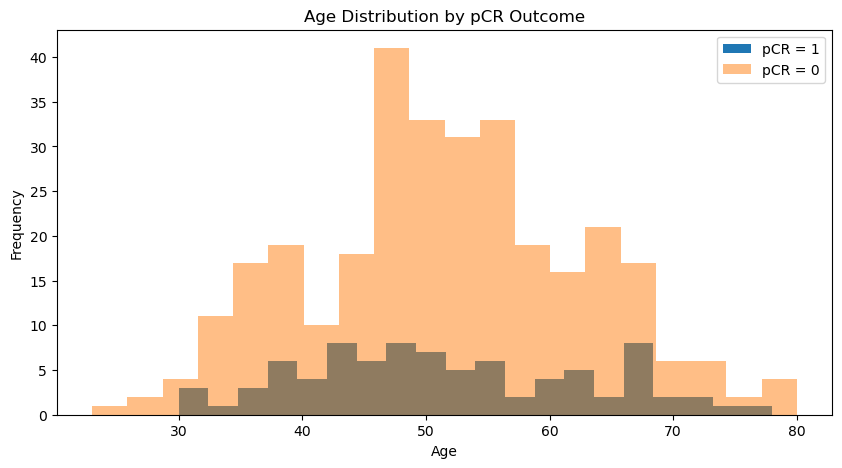

In [20]:
# Visualization of age distribution by pCR outcome.
plt.figure(figsize=(10, 5))
plt.hist(processed_cancer_df[processed_cancer_df['pCR (outcome)'] == 1]['Age'], bins=20, alpha=1, label='pCR = 1')
plt.hist(processed_cancer_df[processed_cancer_df['pCR (outcome)'] == 0]['Age'], bins=20, alpha=0.5, label='pCR = 0')

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution by pCR Outcome')
plt.legend(loc='upper right')
plt.show()

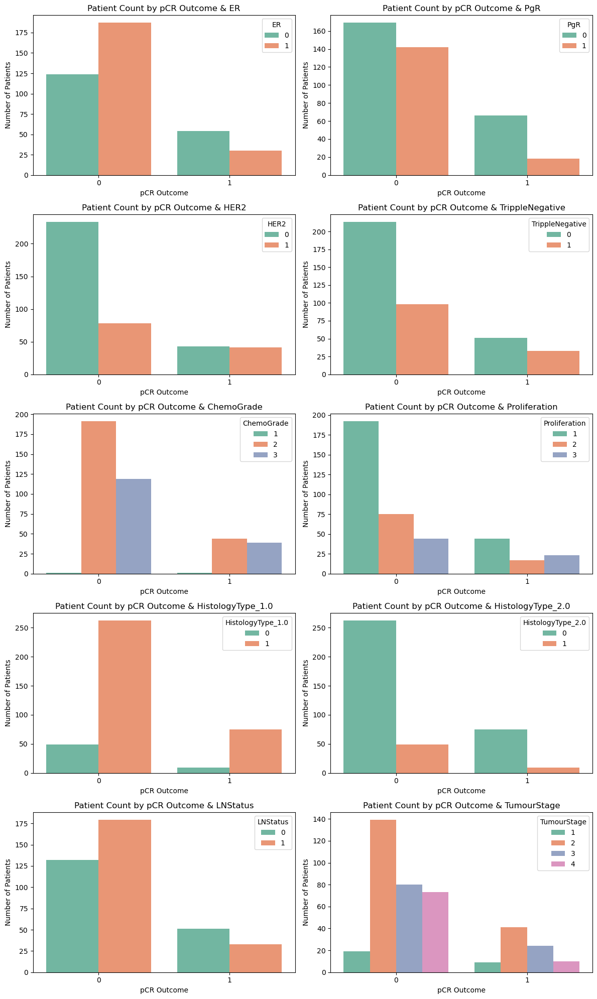

In [21]:
# Visualization of categorical features by pCR outcome.
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(12, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.countplot(
        x='pCR (outcome)', 
        hue=col, 
        data=processed_cancer_df, 
        ax=axes[i],
        palette='Set2'
    )
    
    axes[i].set_title(f'Patient Count by pCR Outcome & {col}')
    axes[i].set_xlabel('pCR Outcome')
    axes[i].set_ylabel('Number of Patients')
    axes[i].legend(title=col, loc='upper right')

plt.tight_layout()
plt.show()




In [22]:
# Overlapping distribution plots for image features by pCR outcome.
image_features = [col for col in processed_cancer_df.columns if col not in categorical_features + ['Age', 'pCR (outcome)', 'RelapseFreeSurvival (outcome)']]

ncols = 2
nrows = math.ceil(len(image_features) / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, nrows * 4))
axes = axes.flatten()

for i, col in enumerate(image_features):
    sns.kdeplot(
        data=processed_cancer_df[processed_cancer_df['pCR (outcome)'] == 1], 
        x=col, 
        fill=True, 
        alpha=0.5, 
        label='pCR = 1',
        ax=axes[i]
    )
    sns.kdeplot(
        data=processed_cancer_df[processed_cancer_df['pCR (outcome)'] == 0], 
        x=col, 
        fill=True, 
        alpha=0.5, 
        label='pCR = 0',
        ax=axes[i]
    )
    
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

In [23]:
# Fisher's Exact Test for binary categorical features.
for col in categorical_features:
    contingency_table = pd.crosstab(processed_cancer_df[col], processed_cancer_df['pCR (outcome)'])
    odds_ratio, p_value = fisher_exact(contingency_table)
    
    print(f"Feature: {col:18s} | Odds Ratio: {odds_ratio:.2f} | P-value: {p_value:.5f}")

Feature: ER                 | Odds Ratio: 0.37 | P-value: 0.00007
Feature: PgR                | Odds Ratio: 0.32 | P-value: 0.00005
Feature: HER2               | Odds Ratio: 2.85 | P-value: 0.00005
Feature: TrippleNegative    | Odds Ratio: 1.41 | P-value: 0.19275
Feature: ChemoGrade         | Odds Ratio: 0.01 | P-value: 0.14790
Feature: Proliferation      | Odds Ratio: 0.00 | P-value: 0.02130
Feature: HistologyType_1.0  | Odds Ratio: 1.56 | P-value: 0.29891
Feature: HistologyType_2.0  | Odds Ratio: 0.64 | P-value: 0.29891
Feature: LNStatus           | Odds Ratio: 0.48 | P-value: 0.00313
Feature: TumourStage        | Odds Ratio: 0.00 | P-value: 0.07410


After analysing all the features with respect to the classification target, it is not visible any simple pattern that would allow to boost the prediction over pCR outcome. Some clinical features seem to be better predictors as their frequency is opposite depending on the target outcome. This is demonstrated in ER and HER2, however, due to the class imbalance there is not a visible causality. Moreover, the distribution of the numerical (age and image) features always have an overlapping behavior when separated by the target outcome. Furthermore, using Fisher's Exact it was possible to identify that some clinical categorical features have a statistical significance that is too low to consider dropping some of these to decrease dimensionality and evaluate if they present an improvement on the machine learning models. This aligns with the need to reduce the dimensionality through the manipulation of the image features (probably using PCA or LDA).

##### Analysis for regression task.

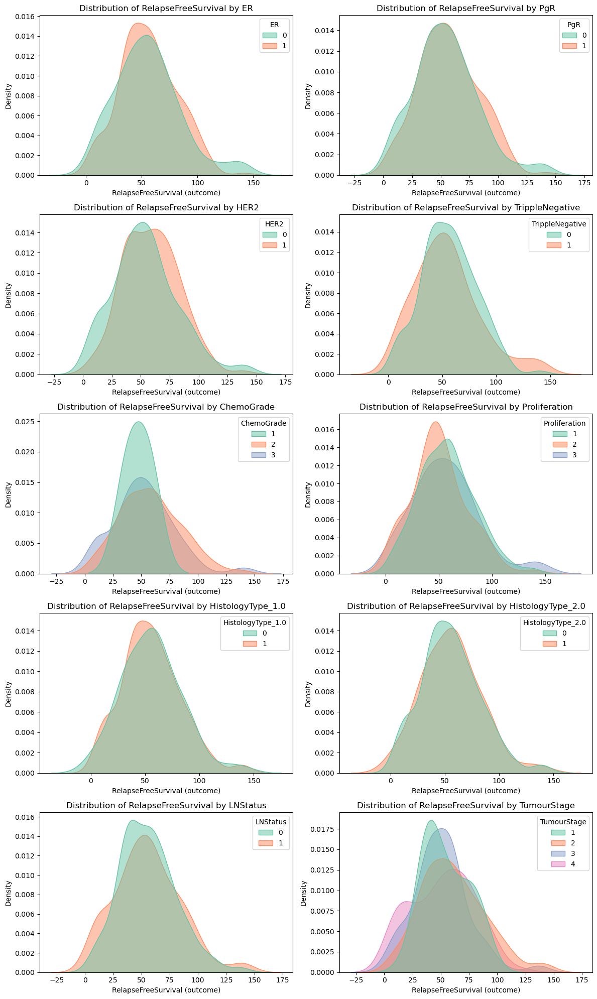

In [24]:
# Distribution of Relapse Free Survival outcome by each categorial feature.
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(12,20))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    sns.kdeplot(
        data=processed_cancer_df,
        x='RelapseFreeSurvival (outcome)',
        hue=col,
        fill=True,
        alpha=0.5,
        common_norm=False,
        palette='Set2',
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of RelapseFreeSurvival by {col}')
    axes[i].set_xlabel('RelapseFreeSurvival (outcome)')
    axes[i].set_ylabel('Density')

plt.tight_layout()
plt.show()

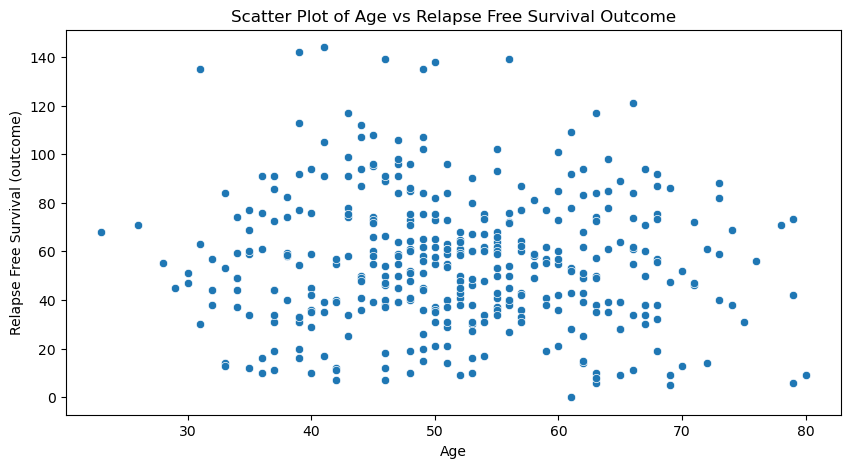

In [25]:
# Scatter plot of Age and Relapse Free Survival outcome.
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=processed_cancer_df,
    x='Age',
    y='RelapseFreeSurvival (outcome)',
)

plt.title('Scatter Plot of Age vs Relapse Free Survival Outcome')
plt.xlabel('Age')
plt.ylabel('Relapse Free Survival (outcome)')
plt.show()




In [26]:
# Scatter plots of RelapseFreeSurvival (outcome) against each image feature.
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, nrows * 4))
axes = axes.flatten()

for i, col in enumerate(image_features):
    sns.scatterplot(
        data=processed_cancer_df,
        x=col,
        y='RelapseFreeSurvival (outcome)',
        ax=axes[i]
    )
    
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Relapse Free Survival (outcome)')

plt.tight_layout()
plt.show()

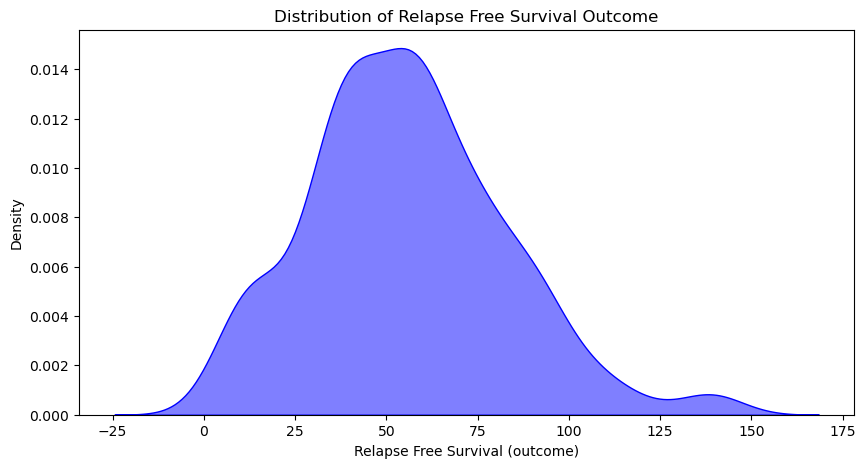

In [27]:
# Distribution of Relapse Free Survival outcome.
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=processed_cancer_df,
    x='RelapseFreeSurvival (outcome)',
    fill=True,
    alpha=0.5,
    color='blue'
)
plt.xlabel('Relapse Free Survival (outcome)')
plt.ylabel('Density')
plt.title('Distribution of Relapse Free Survival Outcome')
plt.show()

In [28]:
# Statistical test to meassure relevance of the categorical features for regression task.
binary_features = [
    'ER', 
    'PgR', 
    'HER2', 
    'TrippleNegative', 
    'LNStatus', 
    'HistologyType_1.0', 
    'HistologyType_2.0'
]

multi_categorical_features = [
    'ChemoGrade', 
    'Proliferation', 
    'TumourStage'
]

# Mann-Whitney U Test for the binary features
print("MANN-WHITNEY U TEST")
for col in binary_features:
    group0 = processed_cancer_df[processed_cancer_df[col] == 0]['RelapseFreeSurvival (outcome)']
    group1 = processed_cancer_df[processed_cancer_df[col] == 1]['RelapseFreeSurvival (outcome)']
    
    u_stat, p_value = mannwhitneyu(group0, group1, alternative='two-sided')
    print(f"Feature: {col:18s} | U-Statistic: {u_stat:8.2f} | P-value: {p_value:.5f}")

print("\n")

# Kruskal-Wallis Test for the multi-class categorical features.
print("KRUSKAL-WALLIS TEST")
for col in multi_categorical_features:
    groups = [group['RelapseFreeSurvival (outcome)'].values for _, group in processed_cancer_df.groupby(col)]
    
    h_stat, p_value = kruskal(*groups)
    print(f"Feature: {col:18s} | H-Statistic: {h_stat:8.4f} | P-value: {p_value:.5f}")

MANN-WHITNEY U TEST
Feature: ER                 | U-Statistic: 18710.00 | P-value: 0.59355
Feature: PgR                | U-Statistic: 17641.00 | P-value: 0.29828
Feature: HER2               | U-Statistic: 14371.00 | P-value: 0.04887
Feature: TrippleNegative    | U-Statistic: 18604.50 | P-value: 0.21936
Feature: LNStatus           | U-Statistic: 19465.50 | P-value: 0.95278
Feature: HistologyType_1.0  | U-Statistic:  9824.00 | P-value: 0.94986
Feature: HistologyType_2.0  | U-Statistic:  9722.00 | P-value: 0.94986


KRUSKAL-WALLIS TEST
Feature: ChemoGrade         | H-Statistic:   5.5149 | P-value: 0.06345
Feature: Proliferation      | H-Statistic:   5.1479 | P-value: 0.07623
Feature: TumourStage        | H-Statistic:   9.7626 | P-value: 0.02070


As with the classification target, the analysis for the predictors on the continuous target variable revealed that there is no visible pattern with any of the features that could be deterministic for prediction. Here, the statistical tests revealed that even less clinical features have relevant statistical significance, which will be considered during the training phase. Moreover, this analysis further supports the need of using PCA with the image features, as they do not provide deterministic information by their own. While the variables where evaluated in an individual basis, the later steps will not inmediately descard them, as multi-factor effects may still be visible in pertinent machine learning algorithms. Finally, the dataset suggests that a non-linear model could be more suitable due to the mix of variables and scattered data.

##### Image Feature Dimensionality Reduction Analysis

In [29]:
# Standarize image features.
scaler = StandardScaler()
scaled_image_features = scaler.fit_transform(processed_cancer_df[image_features])

# Fit Principal Component Analysis (PCA).
pca = PCA()
pca.fit(scaled_image_features)

# Extract eigenvalues and explained variance ratio.
eigenvalues = pca.explained_variance_
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

# Summary table of PCA results.
pca_summary = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Explained Variance (%)': explained_variance_ratio,
    'Cumulative Variance (%)': cumulative_explained_variance
})

pca_summary

,Component,Eigenvalue,Explained Variance (%),Cumulative Variance (%)
0,PC1,3.4915e+01,3.2548e-01,0.3255
1,PC2,1.5633e+01,1.4573e-01,0.4712
2,PC3,1.3175e+01,1.2282e-01,0.5940
3,PC4,1.2306e+01,1.1472e-01,0.7087
4,PC5,6.6569e+00,6.2057e-02,0.7708
5,PC6,5.1286e+00,4.7810e-02,0.8186
6,PC7,3.3749e+00,3.1461e-02,0.8501
7,PC8,2.2804e+00,2.1258e-02,0.8713
8,PC9,2.1224e+00,1.9785e-02,0.8911
9,PC10,1.4017e+00,1.3067e-02,0.9042


In [30]:
# Kaiser criterion to determine the number of significant components.
kaiser_k = np.sum(eigenvalues >= 1)
k_80 = np.argmax(cumulative_explained_variance >= 0.80) + 1
k_90 = np.argmax(cumulative_explained_variance >= 0.90) + 1
k_95 = np.argmax(cumulative_explained_variance >= 0.95) + 1

print(f"Total Image Features: {len(image_features)}")
print(f"Kaiser Criterion (Eigenvalue >= 1.0): {kaiser_k} components ({cumulative_explained_variance[kaiser_k-1]*100:.2f}% variance)")
print(f"80% Variance Threshold: {k_80} components ({cumulative_explained_variance[k_80-1]*100:.2f}% variance)")
print(f"90% Variance Threshold: {k_90} components ({cumulative_explained_variance[k_90-1]*100:.2f}% variance)")
print(f"95% Variance Threshold: {k_95} components ({cumulative_explained_variance[k_95-1]*100:.2f}% variance)\n")

Total Image Features: 107
Kaiser Criterion (Eigenvalue >= 1.0): 13 components (93.60% variance)
80% Variance Threshold: 6 components (81.86% variance)
90% Variance Threshold: 10 components (90.42% variance)
95% Variance Threshold: 15 components (95.16% variance)



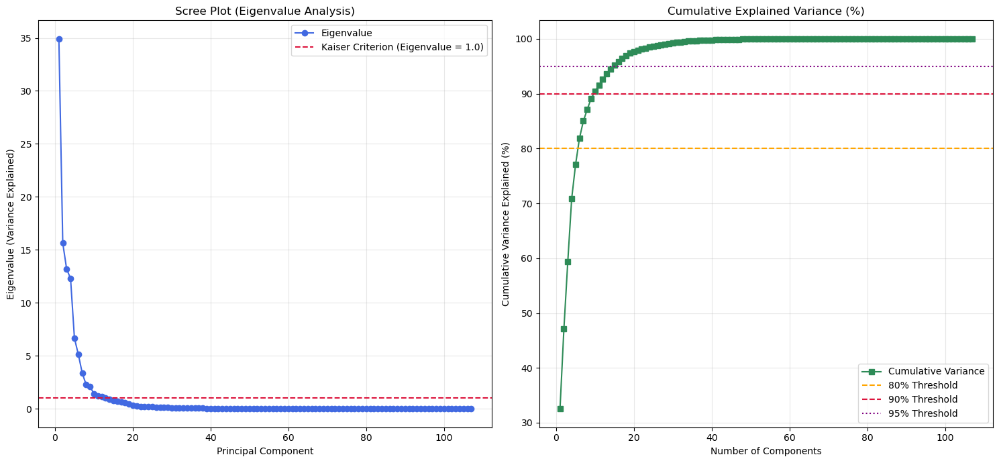

In [31]:
# Visualization of Scree plot and Cumulative Variance plot.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))
components_range = np.arange(1, len(eigenvalues) + 1)

ax1.plot(components_range, eigenvalues, marker='o', linestyle='-', color='royalblue', label='Eigenvalue')
ax1.axhline(y=1.0, color='crimson', linestyle='--', label='Kaiser Criterion (Eigenvalue = 1.0)')
ax1.set_title('Scree Plot (Eigenvalue Analysis)')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Eigenvalue (Variance Explained)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(components_range, cumulative_explained_variance * 100, marker='s', linestyle='-', color='seagreen', label='Cumulative Variance')
ax2.axhline(y=80, color='orange', linestyle='--', label='80% Threshold')
ax2.axhline(y=90, color='crimson', linestyle='--', label='90% Threshold')
ax2.axhline(y=95, color='purple', linestyle=':', label='95% Threshold')
ax2.set_title('Cumulative Explained Variance (%)')
ax2.set_xlabel('Number of Components')
ax2.set_ylabel('Cumulative Variance Explained (%)')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

According to the performed analysis, the decision is to apply PCA and reduce the image features to 13. These will help to reduce dimensionality to prevent overfitting and eliminating 94 will also preserve importan information while eliminating possible multicolinearity. In the end, this aligns with medical papers that predict on data that transform images into numerical features.

## MACHINE LEARNING MODELS TRAINING EVALUATION

##### Classification.

In [32]:
# Load classification cross-validation tuning summary and test set metrics.
clf_cv_df = pd.read_excel("results/classification/cv_tuning_summary.xlsx")
clf_test_df = pd.read_excel("results/classification/test_metrics.xlsx")

print("CLASSIFICATION — 5-FOLD CV TUNING SUMMARY")
display(clf_cv_df)

print("\nCLASSIFICATION — TEST SET EVALUATION METRICS")
display(clf_test_df)

CLASSIFICATION — 5-FOLD CV TUNING SUMMARY


,Model,Best CV Score,Best Parameters
0,Random Forest,0.6697,"{'max_depth': 6, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 300}"
1,SVM,0.6251,"{'C': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}"
2,XGBoost,0.6495,"{'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 150, 'subsample': 0.8}"
3,Decision Tree,0.5551,"{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 5}"
4,KNN,0.6398,"{'n_neighbors': 9, 'p': 1, 'weights': 'distance'}"
5,Naive Bayes,0.6371,{'var_smoothing': 1e-10}



CLASSIFICATION — TEST SET EVALUATION METRICS


,Model,ROC-AUC,PR-AUC,F1-Score,Balanced Accuracy,Accuracy,Precision,Recall,TN,FP,FN,TP
0,Random Forest,0.7685,0.4784,0.4242,0.6333,0.7595,0.4375,0.4118,53,9,10,7
1,Decision Tree,0.7642,0.3939,0.5455,0.7557,0.6835,0.3947,0.8824,39,23,2,15
2,XGBoost,0.7353,0.4654,0.2400,0.5479,0.7595,0.3750,0.1765,57,5,14,3
3,Naive Bayes,0.7002,0.4977,0.4211,0.6305,0.7215,0.3810,0.4706,49,13,9,8
4,KNN,0.6584,0.3322,0.0000,0.4919,0.7722,0.0000,0.0000,61,1,17,0
5,SVM,0.3311,0.1634,0.2979,0.5204,0.5823,0.2333,0.4118,39,23,10,7


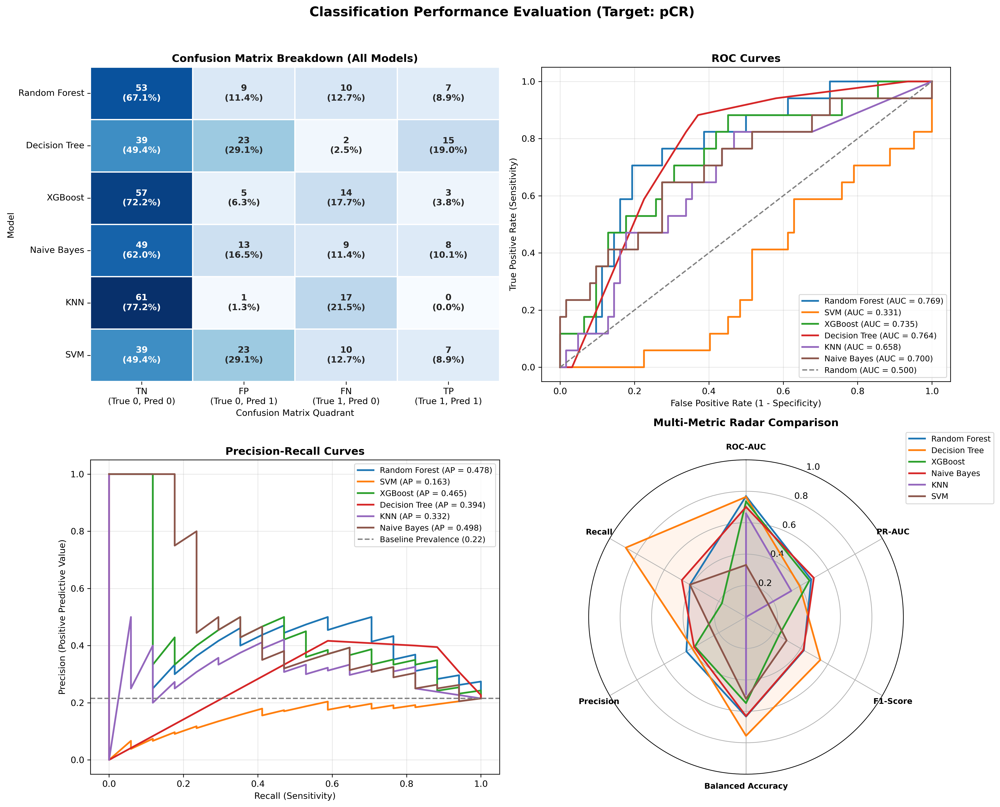

In [33]:
# Display 2x2 classification evaluation grid (Confusion Matrix, ROC, PR, Radar Plot).
display(Image(filename="results/classification/evaluation_2x2_grid.png", width=950))

CLASSIFICATION — SEED STABILITY SUMMARY (10 SEEDS)


,Model,mean,std,min,max
0,Decision Tree,0.7642,0.0000,0.7642,0.7642
1,KNN,0.6584,0.0000,0.6584,0.6584
2,Naive Bayes,0.7002,0.0000,0.7002,0.7002
3,Random Forest,0.7407,0.0195,0.7002,0.7685
4,SVM,0.5676,0.1632,0.3311,0.6689
5,XGBoost,0.7462,0.0113,0.7315,0.7657


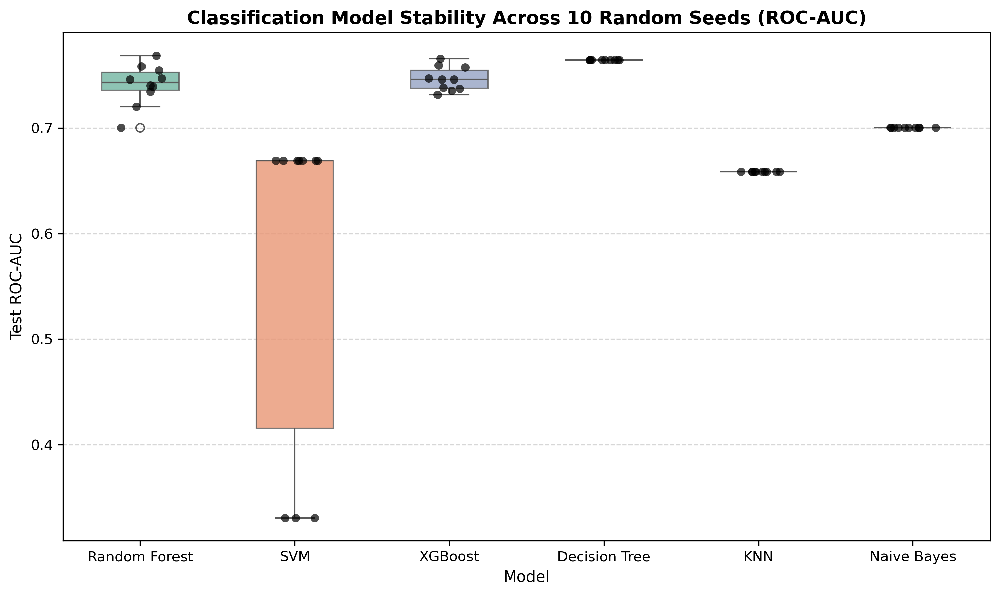

In [34]:
# Load and display classification seed stability summary and boxplot.
clf_stability_df = pd.read_excel("results/classification/seed_stability_summary.xlsx")

print("CLASSIFICATION — SEED STABILITY SUMMARY (10 SEEDS)")
display(clf_stability_df)

display(Image(filename="results/classification/seed_stability_boxplot.png", width=750))

##### Regression.

In [35]:
# Load regression cross-validation tuning summary and test set metrics.
reg_cv_df = pd.read_excel("results/regression/cv_tuning_summary.xlsx")
reg_test_df = pd.read_excel("results/regression/test_metrics.xlsx")

print("REGRESSION — 5-FOLD CV TUNING SUMMARY")
display(reg_cv_df)

print("\nREGRESSION — TEST SET EVALUATION METRICS")
display(reg_test_df)

REGRESSION — 5-FOLD CV TUNING SUMMARY


,Model,Best CV Score,Best Parameters
0,SVM,-25.9585,"{'C': 10.0, 'epsilon': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}"
1,XGBoost,-26.0335,"{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}"
2,Random Forest,-25.8241,"{'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 300}"
3,KNN,-25.7010,"{'n_neighbors': 11, 'p': 1, 'weights': 'distance'}"



REGRESSION — TEST SET EVALUATION METRICS


,Model,RMSE,MAE,MedAE,MSE,R2
0,KNN,27.7698,21.4244,15.0053,771.1613,0.0341
1,Random Forest,27.9462,21.7216,19.4688,780.9904,0.0218
2,XGBoost,28.0519,21.9996,20.5765,786.9085,0.0143
3,SVM,28.4383,22.1411,18.2838,808.7342,-0.0130


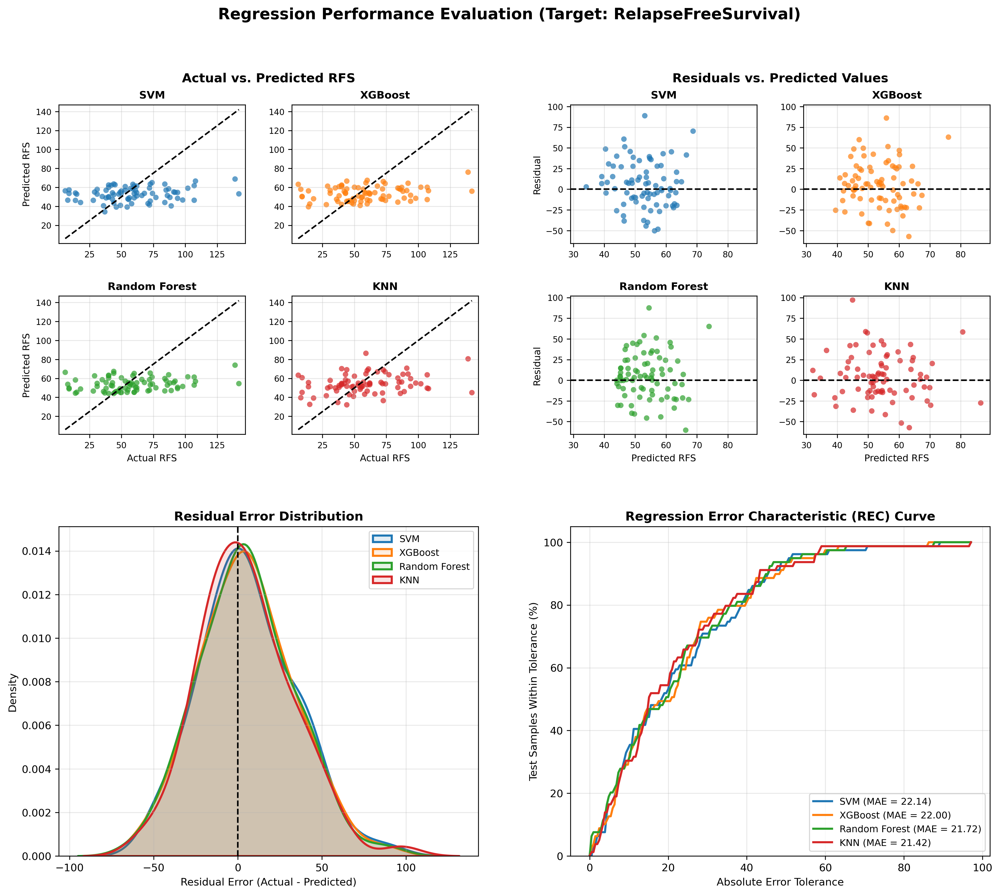

In [36]:
# Display 2x2 regression evaluation grid (Actual vs Predicted, Residuals, KDE, REC Curve).
display(Image(filename="results/regression/evaluation_2x2_grid.png", width=950))

REGRESSION — SEED STABILITY SUMMARY (10 SEEDS)


,Model,mean,std,min,max
0,KNN,27.7698,0.0000,27.7698,27.7698
1,Random Forest,27.9307,0.1100,27.7273,28.1346
2,SVM,28.4383,0.0000,28.4383,28.4383
3,XGBoost,28.1755,0.2144,27.7888,28.5103


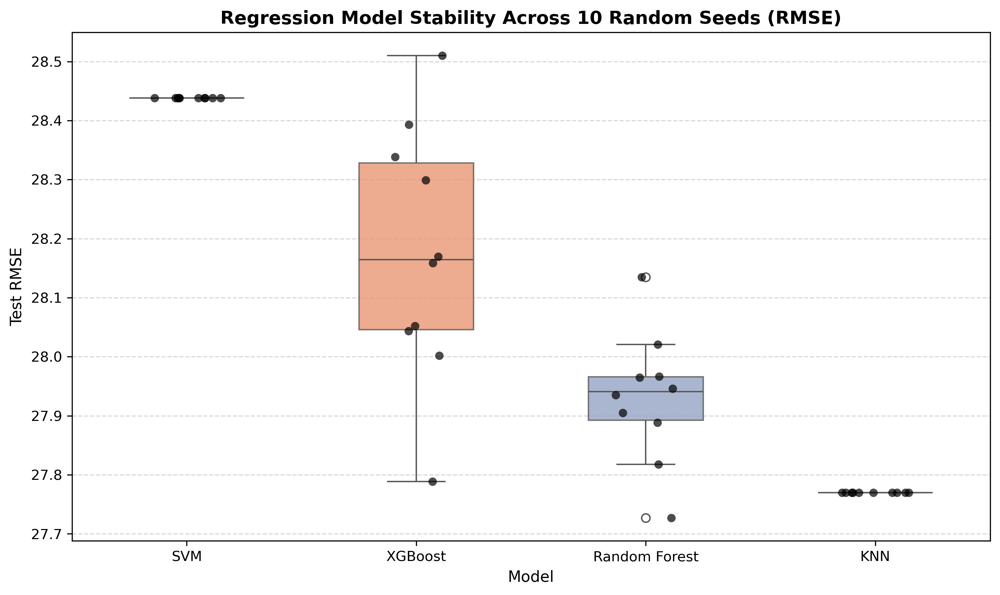

In [37]:
# Load and display regression seed stability summary and boxplot.
reg_stability_df = pd.read_excel("results/regression/seed_stability_summary.xlsx")

print("REGRESSION — SEED STABILITY SUMMARY (10 SEEDS)")
display(reg_stability_df)

display(Image(filename="results/regression/seed_stability_boxplot.png", width=750))